# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3


In [2]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:
# Write your code here

#S = ...
S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
#theta = ...

theta = np.array([0.3, 0.7])

#bias = ...
bias = 0.5

# 1. Compute linear combination z
#z = ...
z = S @ theta + bias

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
#probabilities = ...
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails
#predicted_spam = ...
predicted_spam = probabilities >= 0.5


In [4]:
# Auto-graded cell (S)
# Skip it

In [5]:
# Auto-graded cell (theta)
# Skip it

In [6]:
# Auto-graded cell (bias)
# Skip it

In [7]:
# Auto-graded cell (z)
# Skip it

In [8]:
# Auto-graded cell (probabilities)
# Skip it

In [9]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [10]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [11]:
# Auto graded cell (log)
# skip it

In [12]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
indexes = rng.choice(log.index, 12, replace=False)

log.loc[indexes, "failed_attempts"] = rng.integers(5, 11, 12)

print(log.head())

     user  hour  failed_attempts country  duration_min
0  yacine     2                0      DZ          24.0
1  yacine    23                0      FR          23.2
2    nour    11                0      FR           4.8
3   karim     9                0      DZ           4.2
4     ali    17                0      DZ          21.8


In [13]:
# Autograded cell (Failed attempts)
# Skip it

In [14]:
# Insert 10 missing values randomly

# Write your code here
indexes = rng.choice(log.index, 10, replace=False)

log.loc[indexes, "duration_min"] = np.nan

print(log.isnull().sum())

user                0
hour                0
failed_attempts     0
country             0
duration_min       10
dtype: int64


In [15]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [16]:
# Write your code here
result = log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)]

print(len(result))

# ru_log_at_least_five_attempts = ...
ru_log_at_least_five_attempts = len(result)

1


In [17]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [18]:
# Write your code here
result = log.groupby("user")["failed_attempts"].sum()

result = result.sort_values(ascending=False)

print(result)
print("User with highest failed attempts:", result.index[0])

# user_max_failed_attempts =
user_max_failed_attempts = result.index[0]

print("User with highest failed attempts:", user_max_failed_attempts)

user
karim     51
nour      45
ali       44
yacine    43
sara      36
Name: failed_attempts, dtype: int64
User with highest failed attempts: karim
User with highest failed attempts: karim


In [19]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [20]:
# Write your code here
log["long_session"] = (log["duration_min"] > 30).astype(int)

print(log.head())
# log['long_session'] = ...
log["long_session"] = (log["duration_min"] > 30).astype(int)

print(log.head())

     user  hour  failed_attempts country  duration_min  long_session
0  yacine     2                0      DZ          24.0             0
1  yacine    23                0      FR          23.2             0
2    nour    11                0      FR           4.8             0
3   karim     9                0      DZ           4.2             0
4     ali    17                0      DZ          21.8             0
     user  hour  failed_attempts country  duration_min  long_session
0  yacine     2                0      DZ          24.0             0
1  yacine    23                0      FR          23.2             0
2    nour    11                0      FR           4.8             0
3   karim     9                0      DZ           4.2             0
4     ali    17                0      DZ          21.8             0


In [21]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

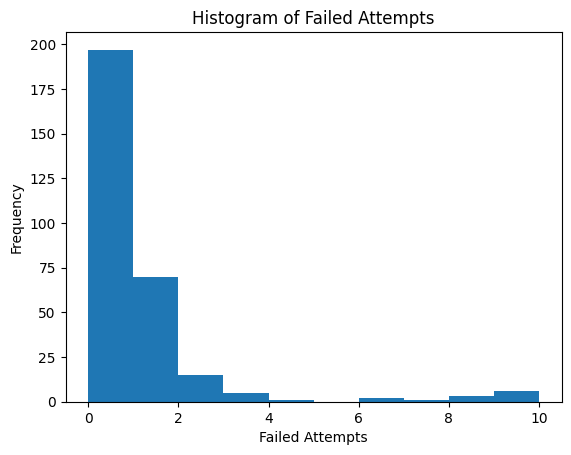

In [22]:
# Draw the histogram of failed_attempts.
# Write your code here
plt.hist(log["failed_attempts"].dropna())

plt.xlabel("Failed Attempts")
plt.ylabel("Frequency")
plt.title("Histogram of Failed Attempts")

plt.show()

In [23]:
# Auto-graded cell - Skip it...

In [24]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [26]:
# Write your code here
# answer_q2 = "B"


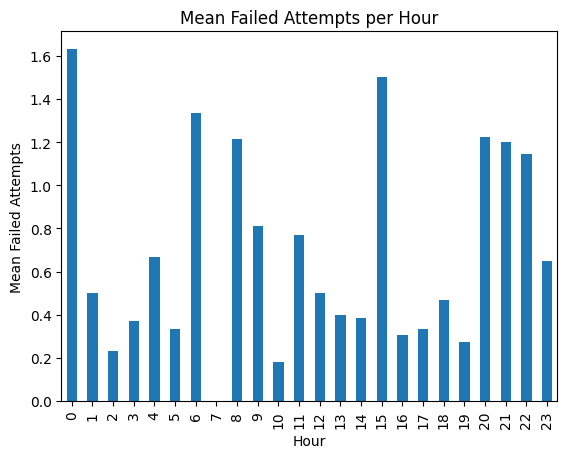

In [25]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
result = log.groupby("night")["failed_attempts"].mean()

result.plot(kind="bar")

plt.xlabel("Night")
plt.ylabel("Mean Failed Attempts")
plt.title("Mean Failed Attempts per Night")

plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# X[:, 2] returns all rows from the third column of array X.
# Please write a sentence response instead of code

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [ ]:
# Write your code here
df.isnull().sum()

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
# Write your code here
# Box plot

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
# To put all features on a similar scale so that large values do not dominate the model.

Commit the logins_clean.csv.(0.5 point)

In [ ]:
# save the cleaned table in login_clean.csv
# Write your code here
log.to_csv("login_clean.csv", index=False)

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [ ]:
# Write your code here
# Read the cleaned CSV file
df = pd.read_csv("login_clean.csv")

# Select the columns
cols = ["hour", "failed_attempts", "duration_min", "night"]

# Create matrix X
X = df[cols].to_numpy()

# Scale the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

# Print the shape
print(X.shape)

In [ ]:
import numpy as np
import pandas as pd
